# Интеллектуальный анализ данных – весна 2026
# Домашнее задание 6: классификация текстов

Правила:



*   Домашнее задание оценивается в 10 баллов.
*   Можно использовать без доказательства любые результаты, встречавшиеся на лекциях или семинарах по курсу, если получение этих результатов не является вопросом задания.
*  Можно использовать любые свободные источники с *обязательным* указанием ссылки на них.
*  Плагиат не допускается. При обнаружении случаев списывания, 0 за работу выставляется всем участникам нарушения, даже если можно установить, кто у кого списал.
*  Старайтесь сделать код как можно более оптимальным. В частности, будет штрафоваться использование циклов в тех случаях, когда операцию можно совершить при помощи инструментов библиотек, о которых рассказывалось в курсе.
* Если в задании есть вопрос на рассуждение, то за отсутствие ответа на него балл за задание будет снижен вполовину.

В этом домашнем задании вам предстоит построить классификатор текстов.

Будем предсказывать эмоциональную окраску твиттов о коронавирусе.



In [ ]:
import numpy as np
import pandas as pd
from typing import  List
import matplotlib.pyplot as plt
import seaborn as sns
from string import punctuation
import warnings
warnings.filterwarnings('ignore')
from collections import defaultdict

In [ ]:
df = pd.read_csv('/content/tweets_coronavirus.csv', encoding='latin-1')
df.sample(4)

,UserName,ScreenName,Location,TweetAt,OriginalTweet,Sentiment
25490,35023,79975,"Lagos, Nigeria",06-04-2020,President Muhammadu Buhari has given approval ...,Positive
22954,31841,76793,Taiwan,04-04-2020,@ft_variations @MatthewACherry I guess those p...,Negative
13250,19878,64830,NYC Area & Shiraz Iran,22-03-2020,Anyone else getting their Ninja on when they h...,Negative
18769,26644,71596,"Manhattan, NYC",25-03-2020,VIDEO: Warrenton man licks toiletries in Misso...,Extremely Negative


Для каждого твитта указано:


*   UserName - имя пользователя, заменено на целое число для анонимности
*   ScreenName - отображающееся имя пользователя, заменено на целое число для анонимности
*   Location - местоположение
*   TweetAt - дата создания твитта
*   OriginalTweet - текст твитта
*   Sentiment - эмоциональная окраска твитта (целевая переменная)



## Задание 1 Подготовка (0.5 балла)

Целевая переменная находится в колонке `Sentiment`.  Преобразуйте ее таким образом, чтобы она стала бинарной: 1 - если у твитта положительная или очень положительная эмоциональная окраска и 0 - если отрицательная или очень отрицательная.

In [ ]:
df['Sentiment'].value_counts()

,count
Sentiment,
Positive,11422
Negative,9917
Extremely Positive,6624
Extremely Negative,5481


In [ ]:
df['Sentiment_int'] = df['Sentiment'].replace({'Positive': 1, 'Extremely Positive': 1, 'Negative': 0, 'Extremely Negative': 0}).astype(int)

Сбалансированы ли классы?

In [ ]:
sum_pos = (df['Sentiment_int'] == 1).sum()
pos = sum_pos / len(df['Sentiment_int']) * 100
print(f'Доля положительного класса = {pos:.2f}%')

Доля положительного класса = 53.96%


**Ответ:** Да, классы сбалансированы
---



Выведете на экран информацию о пропусках в данных. Если пропуски присутствуют заполните их строкой 'Unknown'.

In [ ]:
print(f'Количество пропусков: {df.isna().sum().sum()}')

Количество пропусков: 7049


In [ ]:
df.isna().sum().sort_values(ascending=False)

,0
Location,7049
UserName,0
ScreenName,0
TweetAt,0
OriginalTweet,0
Sentiment,0
Sentiment_int,0


In [ ]:
df.fillna('Unknown', inplace=True)

In [ ]:
df.isna().sum().sort_values()

,0
UserName,0
ScreenName,0
Location,0
TweetAt,0
OriginalTweet,0
Sentiment,0
Sentiment_int,0


Разделите данные на обучающие и тестовые в соотношении 7 : 3 и укажите `random_state=0`

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X = df.iloc[:, :-1]
Y = df.iloc[:, -1]


X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.3, random_state=0)

## Задание 2 Токенизация (3 балла)

Постройте словарь на основе обучающей выборки и посчитайте количество встреч каждого токена с использованием самой простой токенизации - деления текстов по пробельным символам и приведения токенов в нижний регистр.

In [ ]:
tokens_count = defaultdict(int)
for twit in X_train['OriginalTweet']:
    twit = twit.lower()
    tokens = twit.split()
    for token in tokens:
        tokens_count[token] += 1


Какой размер словаря получился?

In [ ]:
print(f'Размер словаря: {len(tokens_count)}')

Размер словаря: 79755


Выведите 10 самых популярных токенов с количеством встреч каждого из них. Объясните, почему именно эти токены в топе.

In [ ]:
sorted_tokens_count = sorted(tokens_count.items(), key = lambda x: x[1], reverse=True)
sorted_tokens_count[:10]

[('the', 26815),
 ('to', 23373),
 ('and', 14684),
 ('of', 13012),
 ('a', 11737),
 ('in', 11198),
 ('for', 8566),
 ('#coronavirus', 8223),
 ('is', 7383),
 ('are', 7050)]

**Ответ:** Эти слова являются стоп-словами, они встречаются в любом тексте, поскольку являются связующими. #coronavirus как главная тема твитов.



Удалите стоп-слова из словаря и выведите новый топ-10 токенов (и количество встреч) по популярности.  Что можно сказать  о нем?

In [ ]:
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')
stop_words = set(stopwords.words('english'))
clean_dickt = {}
for w, count in sorted_tokens_count:
    if w not in stop_words:
        clean_dickt[w] = count
clean_dickt_sorted = sorted(clean_dickt.items(), key = lambda x: x[1], reverse = True)


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
clean_dickt_sorted[:10]

[('#coronavirus', 8223),
 ('prices', 3891),
 ('food', 3820),
 ('grocery', 3469),
 ('supermarket', 3288),
 ('people', 3175),
 ('covid-19', 3173),
 ('store', 3155),
 ('#covid19', 2471),
 ('&amp;', 2314)]

**Ответ:**  # -- YOUR ANSWER HERE --

Также выведите 20 самых непопулярных слов (если самых непопулярных слов больше, выведите любые 20 из них) Почему эти токены непопулярны, требуется ли как-то дополнительно работать с ними?

In [ ]:
clean_dickt_sorted[-20:]

[('skellig', 1),
 ('coast!', 1),
 ('closer!)', 1),
 ('@skelligsix18', 1),
 ('#skelligcoast2kms', 1),
 ('#southkerry', 1),
 ('https://t.co/zjcl195vqs', 1),
 ('@srinivasiyc', 1),
 ('https://t.co/iaek4fwsgz', 1),
 ('premiership', 1),
 ('non-playing', 1),
 ('subsidise', 1),
 ('playersã\x82â\x92', 1),
 ('renewing', 1),
 ('wage!', 1),
 ('flew', 1),
 ('nothing...', 1),
 ('@torontopearson', 1),
 ('@680news', 1),
 ('https://t.co/7j2y3rsld9', 1)]

**Ответ:** Они непопулярны, потому что чаще всего это какие-то уникальные ссылки или теги, либо редкие слова, либо банально слова с опечатками либо со знаками препинания.


Теперь воспользуемся токенайзером получше - TweetTokenizer из библиотеки nltk. Примените его и посмотрите на топ-10 популярных слов. Чем он отличается от топа, который получался раньше? Почему?

In [ ]:
from nltk.tokenize import TweetTokenizer

tw_tokens_dickt = defaultdict(int)
tw = TweetTokenizer()
for twit in X_train['OriginalTweet']:
    twit = twit.lower()
    batch = tw.tokenize(twit)
    for word in batch:
        tw_tokens_dickt[word] += 1


Сортируем

In [ ]:
sorted_tw_tokens_dickt = sorted(tw_tokens_dickt.items(), key = lambda x: x[1], reverse = True)
sorted_tw_tokens_dickt[:10]

[('the', 26993),
 ('.', 24118),
 ('to', 23478),
 (',', 17571),
 ('and', 14825),
 ('of', 13044),
 ('a', 11891),
 ('in', 11348),
 ('?', 9524),
 ('#coronavirus', 8808)]

**Ответ:** Здесь мы также видим множество стоп-слов, однако теперь к ним добавлись отдельно стоящие знаки препинания.

Удалите из словаря стоп-слова и пунктуацию, посмотрите на новый топ-10 слов с количеством встреч, есть ли теперь в нем что-то не похожее на слова?

In [ ]:
from string import punctuation

clean_tw_tokens_dickt = {}
for w, count in sorted_tw_tokens_dickt:
    if w not in punctuation and w not in stop_words:
        clean_tw_tokens_dickt[w] = count

In [ ]:
clean_sorted_tw_tokens_dickt = sorted(clean_tw_tokens_dickt.items(), key = lambda x: x[1], reverse = True)
clean_sorted_tw_tokens_dickt[:10]

[('#coronavirus', 8808),
 ('â', 7415),
 ('\x82', 7311),
 ('19', 7167),
 ('covid', 6253),
 ('prices', 4601),
 ('\x92', 4372),
 ('food', 4367),
 ('store', 3877),
 ('supermarket', 3805)]

**Ответ:** Да есть, символ "\x82" это какой-то неотображаемый символ, также есть буквы не из латинского алфавита

Скорее всего в некоторых топах были неотображаемые символы или отдельные буквы не латинского алфавита. Уберем их: удалите из словаря токены из одного символа, позиция которого в таблице Unicode 128 и более (`ord(x) >= 128`)

Выведите топ-10 самых популярных и топ-20 непопулярных слов. Чем полученные топы отличаются от итоговых топов, полученных при использовании токенизации по пробелам? Что теперь лучше, а что хуже?

In [ ]:
giga_clean_dickt = {token: count for token, count in clean_tw_tokens_dickt.items() if not (len(token) == 1 and ord(token) >= 128)}
giga_clean_dickt_sort = sorted(giga_clean_dickt.items(), key = lambda x: x[1], reverse = True)



In [ ]:
giga_clean_dickt_sort[:10]

# Было
# [('#coronavirus', 8223),
#  ('prices', 3891),
#  ('food', 3820),
#  ('grocery', 3469),
#  ('supermarket', 3288),
#  ('people', 3175),
#  ('covid-19', 3173),
#  ('store', 3155),
#  ('#covid19', 2471),
#  ('&amp;', 2314)]

[('#coronavirus', 8808),
 ('19', 7167),
 ('covid', 6253),
 ('prices', 4601),
 ('food', 4367),
 ('store', 3877),
 ('supermarket', 3805),
 ('grocery', 3523),
 ('people', 3463),
 ('#covid19', 2589)]

In [ ]:
giga_clean_dickt_sort[-20:]

[('https://t.co/lw1r0rm7xs', 1),
 ('https://t.co/5cbliqzx7l', 1),
 ('now.when', 1),
 ('milion', 1),
 ('skellig', 1),
 ('@skelligsix18', 1),
 ('#skelligcoast2kms', 1),
 ('#southkerry', 1),
 ('https://t.co/zjcl195vqs', 1),
 ('@srinivasiyc', 1),
 ('https://t.co/iaek4fwsgz', 1),
 ('premiership', 1),
 ('non-playing', 1),
 ('subsidise', 1),
 ('playersã', 1),
 ('renewing', 1),
 ('flew', 1),
 ('@torontopearson', 1),
 ('@680news', 1),
 ('https://t.co/7j2y3rsld9', 1)]

**Ответ:** Среди непопулярных токенов особой разницы нет, среди самых популярных стоит отметить разъединение "covid" и "19", остальные ключевые слова существительныестали встречаться чаще, в силу очистки от знаков препинания и ошибок орфографии

Выведите топ-10 популярных хештегов (токены, первые символы которых - #) с количеством встреч. Что можно сказать о них?

In [ ]:
top_10_tags = {}
for token, count in giga_clean_dickt_sort:
    if token[0] == '#':
        top_10_tags[token] = count

In [ ]:
top_10_tags_sort = sorted(top_10_tags.items(), key = lambda x: x[1], reverse = True)
top_10_tags_sort[:10]

[('#coronavirus', 8808),
 ('#covid19', 2589),
 ('#covid_19', 1734),
 ('#covid2019', 946),
 ('#toiletpaper', 744),
 ('#covid', 641),
 ('#socialdistancing', 465),
 ('#coronacrisis', 448),
 ('#pandemic', 257),
 ('#coronaviruspandemic', 249)]

**Ответ:** в этом топе мы можем наблюдать разные вариации упоминания covid, а также трендовые на тот момент хештеги по типу туалетной бумаги

То же самое проделайте для ссылок на сайт https://t.co Сравнима ли популярность ссылок с популярностью хештегов? Будет ли информация о ссылке на конкретную страницу полезна?

In [ ]:
top_10_https = {}
for token, count in giga_clean_dickt_sort:
    if token[0:12] == 'https://t.co':
        top_10_https[token] = count

In [ ]:
top_10_https_sort = sorted(top_10_https.items(), key = lambda x: x[1], reverse = True)
top_10_https_sort[:10]

[('https://t.co/oxa7swtond', 5),
 ('https://t.co/gp3eusapl8', 4),
 ('https://t.co/deftrui1pfã\x82â', 3),
 ('https://t.co/wrlhyzizaa', 3),
 ('https://t.co/kuwipf1kqw', 3),
 ('https://t.co/zjnrx6dkkn', 3),
 ('https://t.co/3gbbdpdjat', 3),
 ('https://t.co/e2znxajpre', 3),
 ('https://t.co/catkegayoy', 3),
 ('https://t.co/g63rp042ho', 3)]

**Ответ:** Нет, популярность ссылок намного ниже.

Используем опыт предыдущих экспериментов и напишем собственный токенайзер, улучшив TweetTokenizer. Функция tokenize должна:



*   Привести текст в нижний регистр
*   Применить TweetTokenizer для  выделения токенов
*   Удалить стоп-слова, пунктуацию, токены из одного символа с позицией в таблице Unicode 128 и более,  ссылки на t.co



In [ ]:
def custom_tokenizer(text):
    text = text.lower()
    batch = tw.tokenize(text)
    tokens = []
    for token in batch:
        if token not in punctuation and token not in stop_words and not token.startswith('https://t.co/'):
            if len(token) == 1:
                if ord(token) <= 128:
                    tokens.append(token)
            else:
                tokens.append(token)
    return tokens
# ['sample', 'text', '@sample_text', '#sampletext']

In [ ]:
custom_tokenizer('This is sample text!!!! @Sample_text I, \x92\x92 https://t.co/sample  #sampletext')

['sample', 'text', '@sample_text', '#sampletext']

## Задание 3 Векторизация текстов (2 балла)

Обучите CountVectorizer с использованием custom_tokenizer в качестве токенайзера. Как размер полученного словаря соотносится с размером изначального словаря из начала задания 2?

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer(tokenizer = custom_tokenizer)
cv.fit(X_train['OriginalTweet'])

print(len(cv.vocabulary_))

45291


**Ответ:** уменьшение на ~35 тыс.

Посмотрим на какой-нибудь конкретный твитт:

In [ ]:
ind = 9023
X_train.iloc[ind]['OriginalTweet'], X_train.iloc[ind]['Sentiment']

('Nice one @SkyNews lets not panic but show ppl in france queueing for food!!! #CoronavirusOutbreak #COVID2019 brainless!! Ffs',
 'Negative')

Автор твитта не доволен ситуацией с едой во Франции и текст имеет резко негативную окраску.

Примените обученный CountVectorizer для векторизации данного текста, и попытайтесь определить самый важный токен и самый неважный токен (токен, компонента которого в векторе максимальна/минимальна, без учета 0). Хорошо ли они определились, почему?

In [ ]:
tw_text = X_train.iloc[ind]['OriginalTweet']
tw_sentiment =  X_train.iloc[ind]['Sentiment']

trans = cv.transform([tw_text])
non_zero_ind = trans.nonzero()[1]#индексы токенов, которые есть в твитте (по столбцам, поэтому [1])
non_zero_values = trans.data #частоты ненулевых

#на каком месте максимальная/минимальная частота
max_pos = non_zero_values.argmax()
min_pos = non_zero_values.argmin()

#какому индексу соответствует максимальная/минимальная частота
max_idx = non_zero_ind[max_pos]
min_idx = non_zero_ind[min_pos]

#максимальная/минимальная частота
max_freq = non_zero_values[max_pos]
min_freq = non_zero_values[min_pos]

tokens = cv.get_feature_names_out()#получаем сами токены
#обращаемся к токенам по найденным индексам
important_token = tokens[max_idx]
unimportant_token = tokens[min_idx]

print(f'Самый важный токен: {important_token}, встретился {max_freq} раз')
print(f'Самый неважный токен: {unimportant_token}, встретился {min_freq} раз')

Самый важный токен: #coronavirusoutbreak, встретился 1 раз
Самый неважный токен: #coronavirusoutbreak, встретился 1 раз


**Ответ:** определились плохо, потому что это происходит по количеству вхождений в твит, но поскольку все токены встречаются 1 раз, то они все равноценны.

Теперь примените TfidfVectorizer и  определите самый важный/неважный токены. Хорошо ли определились, почему?

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(tokenizer = custom_tokenizer)
tfidf.fit(X_train['OriginalTweet'])

TfidfVectorizer(tokenizer=<function custom_tokenizer at 0x790ac37742c0>)

In [ ]:
trans = tfidf.transform([tw_text])
non_zero_ind = trans.nonzero()[1]#индексы токенов, которые есть в твитте (по столбцам, поэтому [1])
non_zero_values = trans.data #частоты ненулевых

#на каком месте максимальная/минимальная частота
max_pos = non_zero_values.argmax()
min_pos = non_zero_values.argmin()

#какому индексу соответствует максимальная/минимальная частота
max_idx = non_zero_ind[max_pos]
min_idx = non_zero_ind[min_pos]

#максимальная/минимальная частота
max_freq = non_zero_values[max_pos]
min_freq = non_zero_values[min_pos]

tokens = tfidf.get_feature_names_out()#получаем сами токены
#обращаемся к токенам по найденным индексам
important_token = tokens[max_idx]
unimportant_token = tokens[min_idx]

print(f'Самый важный токен: {important_token}, встретился {max_freq} раз')
print(f'Самый неважный токен: {unimportant_token}, встретился {min_freq} раз')

Самый важный токен: brainless, встретился 0.3867641170466375 раз
Самый неважный токен: food, встретился 0.11328893069250721 раз


**Ответ:** Если мы называем важными слова, которые есть в этом твите, но в остальных он редко встрчается, то да, всё получилось, слово 'food' в топе самых популярных токенов, и здесь оно является самым неважным. Однако всё ещё нет гарантий, что по важному слову мы можем определить окрас всего твита.

Найдите какой-нибудь положительно окрашенный твитт, где TfidfVectorizer хорошо (полезно для определения окраски) выделяет важный токен, поясните пример.

*Подсказка:* явно положительные твитты можно искать при помощи положительных слов (good, great, amazing и т. д.)

In [ ]:
X_train[X_train['OriginalTweet'].apply(lambda x: 'nice' in x) & (X_train['Sentiment'] == 'Extremely Positive')].head()

,UserName,ScreenName,Location,TweetAt,OriginalTweet,Sentiment
25,3830,48782,Unknown,16-03-2020,'Hole' Foods...\r\r\n\r\r\n...images from the ...,Extremely Positive
29340,39806,84758,Unknown,09-04-2020,My #blossomwatch today en route to the superma...,Extremely Positive
31640,42719,87671,Valley Of The Kings,12-04-2020,One of the many pluses of social distancing? O...,Extremely Positive
6820,12094,57046,"Edinburgh, Scotland",19-03-2020,Small reminder: be nice to Supermarket staff. ...,Extremely Positive
32051,43230,88182,Unknown,12-04-2020,"Thank you @ShopRiteStores , for keeping your p...",Extremely Positive


In [ ]:
nice_boys = 'The Can banks have seen their stock prices drop 29% since Feb 21. But they should make a very nice profit on these many tens of billions of dollars worth of govt-guaranteed COVID-19 loans. And they are very well capitalized. So they look to me to be a great buy right now.'
vect = tfidf.transform([nice_boys])
non_zero_ind_nice = vect.nonzero()[1]
non_zero_values_nice = vect.data

max_nice_ind = non_zero_values_nice.argmax()

max_nice_val = non_zero_values_nice[max_nice_ind]

ind_huge = non_zero_ind_nice[max_nice_ind]

tokens = tfidf.get_feature_names_out()

imp_token = tokens[ind_huge]

print(f'Самый важный токен: {imp_token}, встретился {max_nice_val} раз')

Самый важный токен: govt-guaranteed, встретился 0.31299088840104355 раз


**Ответ:** в этом примере получилось, что самый важный токен тот, который скорее всего 1 раз встречается в остальных твиттах, поскольку в рамках одного твитта он встречается единажды, и сам по себе является редким соркащением слова "government".

In [ ]:
frequency = tokens_count.get('govt-guaranteed', 0)
print(f"Слово '{'govt-guaranteed'}' встречается {frequency} раз(а)")

Слово 'govt-guaranteed' встречается 1 раз(а)


## Задание 4 Обучение первых моделей (1 балл)

Примените оба векторайзера для получения матриц с признаками текстов.  Выделите целевую переменную.

In [ ]:
X_train_cv = cv.fit_transform(X_train['OriginalTweet'])
X_test_cv = cv.transform(X_test['OriginalTweet'])
X_test_cv

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 177503 stored elements and shape (10034, 45291)>

In [ ]:
X_train_tfidf = tfidf.fit_transform(X_train['OriginalTweet'])
X_test_tfidf = tfidf.transform(X_test['OriginalTweet'])
X_test_tfidf

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 177503 stored elements and shape (10034, 45291)>

Обучите логистическую регрессию на векторах из обоих векторайзеров. Посчитайте долю правильных ответов на обучающих и тестовых данных. Какой векторайзер показал лучший результат? Что можно сказать о моделях?

Используйте `sparse` матрицы (после векторизации), не превращайте их в `numpy.ndarray` или `pd.DataFrame` - может не хватить памяти.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

#Создаем две модели
lg_cv = LogisticRegression(random_state=52)
lg_tfidf = LogisticRegression(random_state=52)

#Обучаем логистическую регрессию на векторе из Countvectorizer
lg_cv.fit(X_train_cv, Y_train)

#Делаем предсказание для Countvectorizer
prediction_cv_train = lg_cv.predict(X_train_cv)
prediction_cv_test = lg_cv.predict(X_test_cv)

#Обучаем логистическую регрессию на векторе из TF-IDF
lg_tfidf.fit(X_train_tfidf, Y_train)

#Делаем предсказание для TF-IDF
prediction_tfidf_train = lg_tfidf.predict(X_train_tfidf)
prediction_tfidf_test = lg_tfidf.predict(X_test_tfidf)

In [ ]:
accuracy_cv_train = accuracy_score(prediction_cv_train, Y_train)
accuracy_cv_test = accuracy_score(prediction_cv_test, Y_test)
accuracy_tfidf_train = accuracy_score(prediction_tfidf_train, Y_train)
accuracy_tfidf_test = accuracy_score(prediction_tfidf_test, Y_test)

print(f"CountVectorizer \n Accuracy on train: {np.round(accuracy_cv_train*100, 3)}% \n Accuracy on test: {np.round(accuracy_cv_test*100, 3)}%")
print(f"TF-IDF \n Accuracy on train: {np.round(accuracy_tfidf_train*100, 3)}% \n Accuracy on test: {np.round(accuracy_tfidf_test*100, 3)}%")

CountVectorizer 
 Accuracy on train: 98.488% 
 Accuracy on test: 86.795%
TF-IDF 
 Accuracy on train: 92.247% 
 Accuracy on test: 85.27%


**Ответ:** Лучший результат показал CountVectorizer, на тренировочной выборке он на 6 % пунктов лучше, на тестовой на 1.5 % пунктов. Однако до этого мы поняли суть работы обеих моделей, CountVectorizer просто считает количество встреч во всех документах, и так определяет важность (вес w), TF-IDF же делает важную поправку, если слово частое, то оно не важно и его вес уменьшается. Поэтому несмотря на то, что на наших данных CV показал результат лучше, TF-IDF является более надежным, более того, мы видим переобучение у CV.

## Задание 5 Стемминг (0.5 балла)

Для уменьшения словаря можно использовать стемминг.

Модифицируйте написанный токенайзер, добавив в него стемминг с использованием SnowballStemmer. Обучите Count- и Tfidf- векторайзеры. Как изменился размер словаря?

In [ ]:
from nltk.stem import SnowballStemmer
stemmer = SnowballStemmer("english")

In [ ]:
def custom_stem_tokenizer(text):
  batch = custom_tokenizer(text)
  tokens = []
  for token in batch:
    tokens.append(stemmer.stem(token))
  return tokens

In [ ]:
custom_stem_tokenizer('This is sample text!!!! @Sample_text I, \x92\x92 https://t.co/sample  #sampletext adding more words to check stemming')
#['sampl', 'text', '@sample_text', '#sampletext', 'ad', 'word', 'check', 'stem']

['sampl', 'text', '@sample_text', '#sampletext', 'ad', 'word', 'check', 'stem']

In [ ]:
cv_2_try = CountVectorizer(tokenizer=custom_stem_tokenizer)
cv_2_try.fit(X_train['OriginalTweet'])
print(len(cv_2_try.vocabulary_))

36635


In [ ]:
tfidf_2_try = TfidfVectorizer(tokenizer=custom_stem_tokenizer)
tfidf_2_try.fit(X_train['OriginalTweet'])
print(len(tfidf_2_try.vocabulary_))

36635


**Ответ** Минус 9000 ячеек

Обучите логистическую регрессию с использованием обоих векторайзеров. Изменилось ли качество? Есть ли смысл применять стемминг?

In [ ]:
X_train_cv = cv_2_try.fit_transform(X_train['OriginalTweet'])
X_test_cv = cv_2_try.transform(X_test['OriginalTweet'])

X_train_tfidf = tfidf_2_try.fit_transform(X_train['OriginalTweet'])
X_test_tfidf = tfidf_2_try.transform(X_test['OriginalTweet'])

In [ ]:
#Создаем две модели
lg_cv_2_try = LogisticRegression(random_state=52)
lg_tfidf_2_try = LogisticRegression(random_state=52)

#Обучаем логистическую регрессию на векторе из Countvectorizer
lg_cv_2_try.fit(X_train_cv, Y_train)

#Делаем предсказание для Countvectorizer
prediction_cv_train = lg_cv_2_try.predict(X_train_cv)
prediction_cv_test = lg_cv_2_try.predict(X_test_cv)

#Обучаем логистическую регрессию на векторе из TF-IDF
lg_tfidf_2_try.fit(X_train_tfidf, Y_train)

#Делаем предсказание для TF-IDF
prediction_tfidf_train = lg_tfidf_2_try.predict(X_train_tfidf)
prediction_tfidf_test = lg_tfidf_2_try.predict(X_test_tfidf)

In [ ]:
accuracy_cv_train = accuracy_score(prediction_cv_train, Y_train)
accuracy_cv_test = accuracy_score(prediction_cv_test, Y_test)
accuracy_tfidf_train = accuracy_score(prediction_tfidf_train, Y_train)
accuracy_tfidf_test = accuracy_score(prediction_tfidf_test, Y_test)

print(f"CountVectorizer \n Accuracy on train: {np.round(accuracy_cv_train*100, 3)}% \n Accuracy on test: {np.round(accuracy_cv_test*100, 3)}%")
print(f"TF-IDF \n Accuracy on train: {np.round(accuracy_tfidf_train*100, 3)}% \n Accuracy on test: {np.round(accuracy_tfidf_test*100, 3)}%")

CountVectorizer 
 Accuracy on train: 97.198% 
 Accuracy on test: 86.695%
TF-IDF 
 Accuracy on train: 91.593% 
 Accuracy on test: 85.659%


Было <br>
CountVectorizer <br>
 Accuracy on train: 98.488% <br>
 Accuracy on test: 86.795%<br>
TF-IDF <br>
 Accuracy on train: 92.247% <br>
 Accuracy on test: 85.27%<br>

**Ответ:** Значимых изменений нет, однако это поддтверждает факт что стемминг полезен, так как он значительно (на 20%) сокращает объем словаря, что ускоряет работу и уменьшае требуемую память, практически не влияя на результат предикта

## Задание  6 Работа с частотами (1.5 балла)

Еще один способ уменьшить количество признаков - это использовать параметры min_df и max_df при построении векторайзера  эти параметры помогают ограничить требуемую частоту встречаемости токена в документах.

По умолчанию берутся все токены, которые встретились хотя бы один раз.



Подберите max_df такой, что размер словаря будет 36651 (на 1 меньше, чем было). Почему параметр получился такой большой/маленький?

In [ ]:
8809/36635

0.24045311860242938

In [ ]:
cv_df = CountVectorizer(tokenizer=custom_stem_tokenizer,
                        max_df = 0.3
                        ).fit(
                            X_train['OriginalTweet']
                            )
print(len(cv_df.vocabulary_))

36634


In [ ]:
X_matrix = cv_df.transform(X_train['OriginalTweet'])

total_freq = X_matrix.sum(axis=0).A1
all_words = cv_df.get_feature_names_out()
word_freq = dict(zip(all_words, total_freq))

top_10 = sorted(word_freq.items(), key=lambda x: x[1], reverse=True)[:10]

In [ ]:
top_10

[('19', np.int64(7167)),
 ('covid', np.int64(6253)),
 ('price', np.int64(5283)),
 ('store', np.int64(4671)),
 ('food', np.int64(4463)),
 ('supermarket', np.int64(4193)),
 ('groceri', np.int64(3760)),
 ('peopl', np.int64(3501)),
 ('shop', np.int64(2796)),
 ('consum', np.int64(2723))]

**Ответ:** Параметр получился таким большим, потому что своей сути он игнорирует те слова, которые всстречаются чаще чем введенный параметр, и он должен быть равен частоте самого популярного слова чтобы выполнить задание. Либо мы можем подставить туда долю (0.3), но тогда параметр будет от 0 до 1

Подберите min_df (используйте дефолтное значение max_df) в CountVectorizer таким образом, чтобы размер словаря был 3700 токенов (при использовании токенайзера со стеммингом), а качество осталось таким же, как и было. Что можно сказать о результатах?

In [ ]:
cv_df = CountVectorizer(tokenizer=custom_stem_tokenizer,
                        min_df=16/36635
                        ).fit(
                            X_train['OriginalTweet']
                            )
print(len(cv_df.vocabulary_))

3688


In [ ]:
X_train_cv = cv_df.fit_transform(X_train['OriginalTweet'])
X_test_cv = cv_df.transform(X_test['OriginalTweet'])

X_train_tfidf = cv_df.fit_transform(X_train['OriginalTweet'])
X_test_tfidf = cv_df.transform(X_test['OriginalTweet'])

In [ ]:
#Создаем две модели
lg_cv_2_try = LogisticRegression(random_state=52)
lg_tfidf_2_try = LogisticRegression(random_state=52)

#Обучаем логистическую регрессию на векторе из Countvectorizer
lg_cv_2_try.fit(X_train_cv, Y_train)

#Делаем предсказание для Countvectorizer
prediction_cv_train = lg_cv_2_try.predict(X_train_cv)
prediction_cv_test = lg_cv_2_try.predict(X_test_cv)

In [ ]:
accuracy_cv_train = accuracy_score(prediction_cv_train, Y_train)
accuracy_cv_test = accuracy_score(prediction_cv_test, Y_test)

print(f"CountVectorizer \n Accuracy on train: {np.round(accuracy_cv_train*100, 3)}% \n Accuracy on test: {np.round(accuracy_cv_test*100, 3)}%")

CountVectorizer 
 Accuracy on train: 92.918% 
 Accuracy on test: 86.835%


In [ ]:
# CountVectorizer
# Accuracy on train: 97.198%
# Accuracy on test: 86.695%

**Ответ:** Получилось снизить переобучение на 4,2 % пункта, сохранив такую же результативность на тестовых данных. Это логичное следствие того, что мы убрали шум, на который модель могла акцентировать своё внимание.

В предыдущих заданиях признаки не скалировались. Отскалируйте данные (при словаре размера 3.7 тысяч, векторизованные CountVectorizer), обучите логистическую регрессию, посмотрите качество и выведите `barplot`, содержащий по 10 токенов, с наибольшим по модулю положительными/отрицательными весами. Что можно сказать об этих токенах?

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler(with_mean=False)
scaler.fit(X_train_cv)

StandardScaler(with_mean=False)

In [ ]:
X_train_cv_scaled = scaler.fit_transform(X_train_cv)
X_test_cv_scaled = scaler.transform(X_test_cv)

In [ ]:
lg_cv_scaled = LogisticRegression(random_state=52)

#Обучаем логистическую регрессию на векторе из Countvectorizer
lg_cv_scaled.fit(X_train_cv_scaled , Y_train)

#Делаем предсказание для Countvectorizer
prediction_cv_train = lg_cv_scaled.predict(X_train_cv_scaled)
prediction_cv_test = lg_cv_scaled.predict(X_test_cv_scaled)

In [ ]:
accuracy_cv_train = accuracy_score(prediction_cv_train, Y_train)
accuracy_cv_test = accuracy_score(prediction_cv_test, Y_test)

print(f"CountVectorizer \n Accuracy on train: {np.round(accuracy_cv_train*100, 3)}% \n Accuracy on test: {np.round(accuracy_cv_test*100, 3)}%")

CountVectorizer 
 Accuracy on train: 94.122% 
 Accuracy on test: 84.503%


In [ ]:
weights = lg_cv_scaled.coef_[0]

array([-0.00630497, -0.00336461,  0.06945645, ...,  0.0128679 ,
        0.01043481, -0.01780464])

In [ ]:
tokens = cv_df.get_feature_names_out()

array(['#2020', '#21daylockdown', '#21dayslockdown', ..., 'zone', 'zoom',
       '\x80'], dtype=object)

In [ ]:
dick_tokens_weights = dict(zip(tokens, weights))
dick_tokens_weights_sort = sorted(dick_tokens_weights.items(), key = lambda x: x[1], reverse = True)
dick_tokens_weights_sort_reverse = sorted(dick_tokens_weights.items(), key = lambda x: x[1])

top_10_weights = []
least_10_weights = []
weight_top = []
weights_least = []
for i in range(10):
    top_10_weights.append(dick_tokens_weights_sort[i][0])
    weight_top.append(dick_tokens_weights_sort[i][1])
for i in range(10):
    least_10_weights.append(dick_tokens_weights_sort_reverse[i][0])
    weights_least.append(dick_tokens_weights_sort_reverse[i][1])

Text(0.5, 1.0, 'Топ-10 самых весомых токенов с + и -')

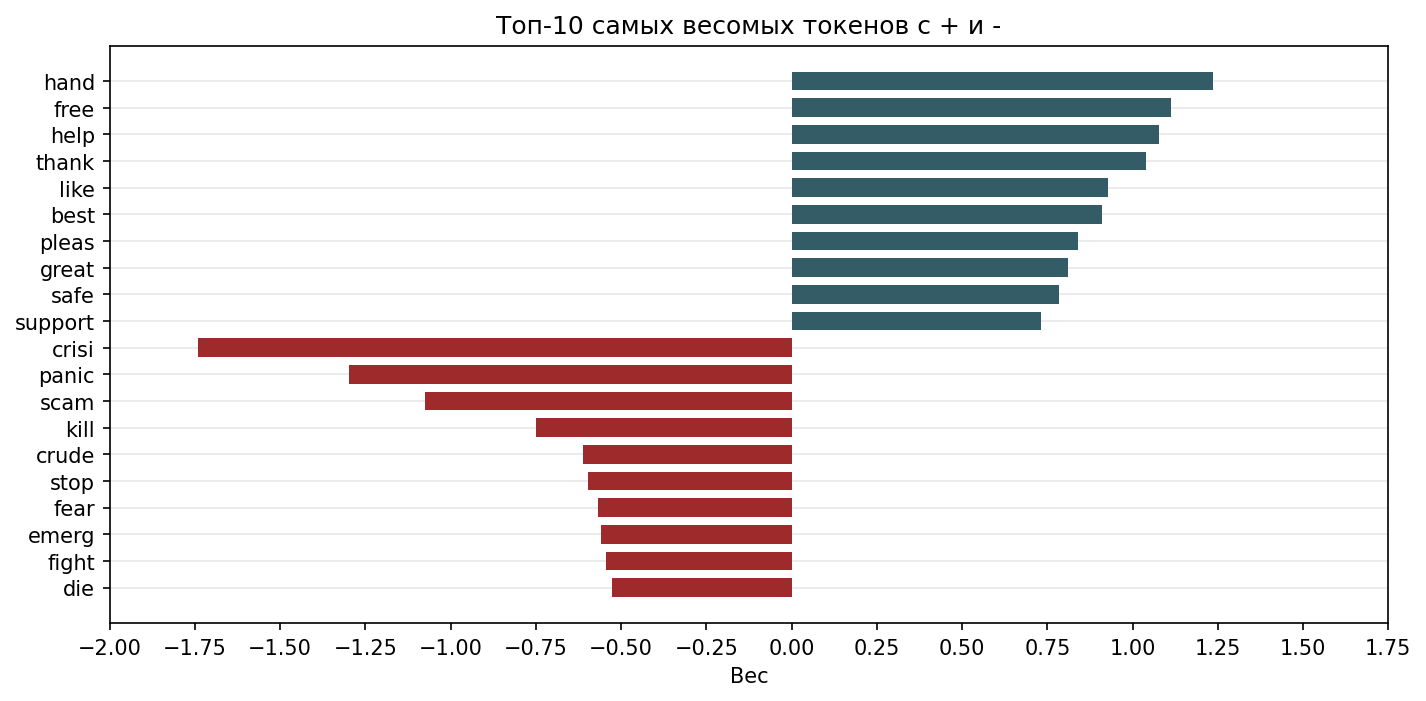

In [ ]:
plt.figure(figsize=(11,5), dpi = 150)
plt.gca().set_axisbelow(True)
plt.barh(top_10_weights, weight_top, color = '#335c67', height=0.7)
plt.barh(least_10_weights, weights_least, color = '#9e2a2b', height=0.7)
plt.gca().invert_yaxis()
plt.xticks(np.arange(-2, 2, 0.25))
plt.grid(axis='y', alpha=0.3, linestyle='-')
plt.xlabel('Вес')
plt.title('Топ-10 самых весомых токенов с + и -')

**Ответ:** Из-за скалирования признаков Accuracy пострадал на 2.5%, поэтому большим вопросом является релевантность его применения в данной ситуации. Что касается слов, то можно смело сказать что модель достаточно качественно определила эмоциональную окраску слов и их потенциальное слияние на твит.

## Задание 7 Другие признаки (1.5 балла)

Мы были сконцентрированы на работе с текстами твиттов и не использовали другие признаки - имена пользователя, дату и местоположение

Изучите признаки UserName и ScreenName. полезны ли они? Если полезны, то закодируйте их, добавьте к матрице с отскалированными признаками, обучите логистическую регрессию, замерьте качество.

**Ответ:** Они не могут иметь смысла, это рандомные числа

Изучите признак TweetAt в обучающей выборке: преобразуйте его к типу datetime и нарисуйте его гистограмму с разделением по цвету на основе целевой переменной. Полезен ли он? Если полезен, то закодируйте его, добавьте к матрице с отскалированными признаками, обучите логистическую регрессию, замерьте качество.

In [ ]:
X_train['DT_TweetAt'] = pd.to_datetime(X_train['TweetAt'], format='%d-%m-%Y')
X_test['DT_TweetAt'] = pd.to_datetime(X_test['TweetAt'], format='%d-%m-%Y')

In [ ]:
positives = X_train[(X_train['Sentiment'] == 'Positive')|(X_train['Sentiment'] == 'Extremely Positive')]['DT_TweetAt']
negatives = X_train[(X_train['Sentiment'] == 'Negative')|(X_train['Sentiment'] == 'Extremely Negative')]['DT_TweetAt']

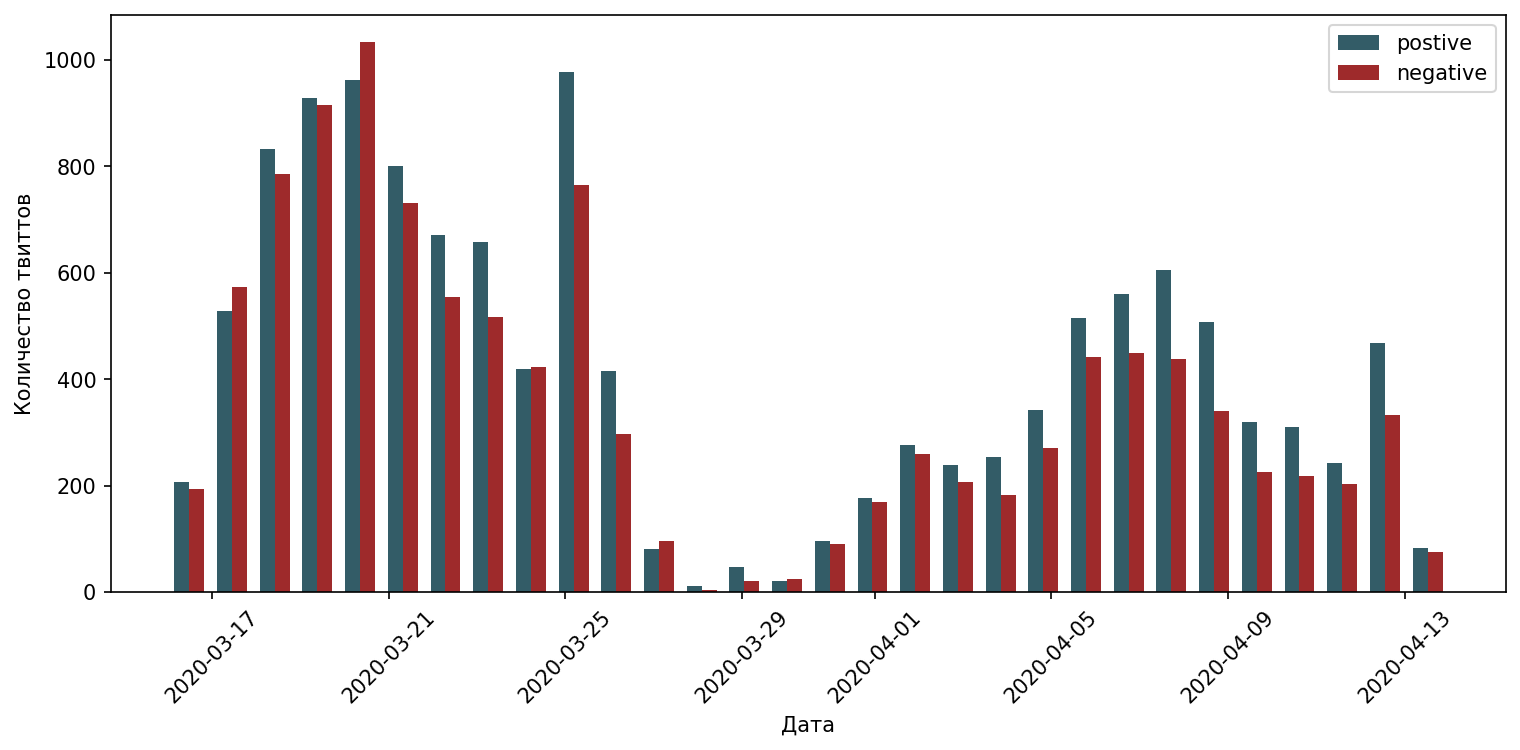

In [ ]:
plt.figure(figsize = (12,5), dpi = 150)
plt.hist([positives, negatives], bins = 30, label = ['postive', 'negative'], color = ['#335c67', '#9e2a2b'], histtype='bar', rwidth=0.7);
plt.xlabel('Дата')
plt.ylabel('Количество твиттов')
plt.xticks(rotation=45)
plt.legend()

**Ответ:** Здесь так же видим, что признак не информативен, единственное, он позволяет проследить динамику написания твитов.


Поработайте с признаком Location в обучающей выборке. Сколько уникальных значений?

In [ ]:
X_train['Location'].value_counts()

,count
Location,
Unknown,4944
London,301
United States,295
"London, England",274
"New York, NY",223
...,...
"Honolulu, Hawai?i",1
SFO,1
"Cleveland Heights , Ohio",1


Постройте гистограмму топ-10 по популярности местоположений (исключая Unknown)

Text(0.5, 0, 'Frequency')

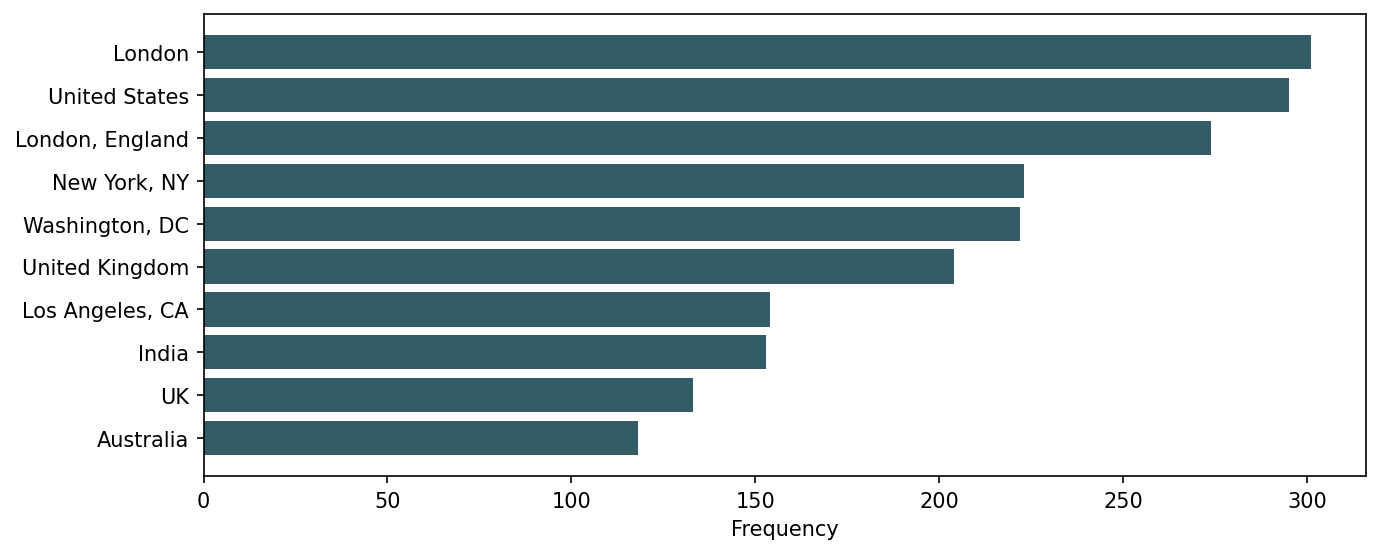

In [ ]:
x = X_train[X_train['Location'] != 'Unknown']['Location'].value_counts().head(10)
plt.figure(figsize = (10,4), dpi = 150)
plt.barh(x.index, x.values, color = '#335c67')
plt.gca().invert_yaxis()
plt.xlabel('Frequency')

Видно, что многие местоположения включают в себя более точное название места, чем другие (Например, у некоторых стоит London, UK; а у некоторых просто UK или United Kingdom).

Создайте новый признак WiderLocation, который содержит самое широкое местоположение (например, из London, UK должно получиться UK). Сколько уникальных категорий теперь? Постройте аналогичную гистограмму.

In [ ]:
def w_location(info):
    if ',' in info:
        info = info.split(', ')
        return info[-1].strip()
    else:
        return info

In [ ]:
X_train['WiderLocation'] = X_train['Location'].apply(w_location)
X_test['WiderLocation'] = X_test['Location'].apply(w_location)

Text(0.5, 0, 'Frequency')

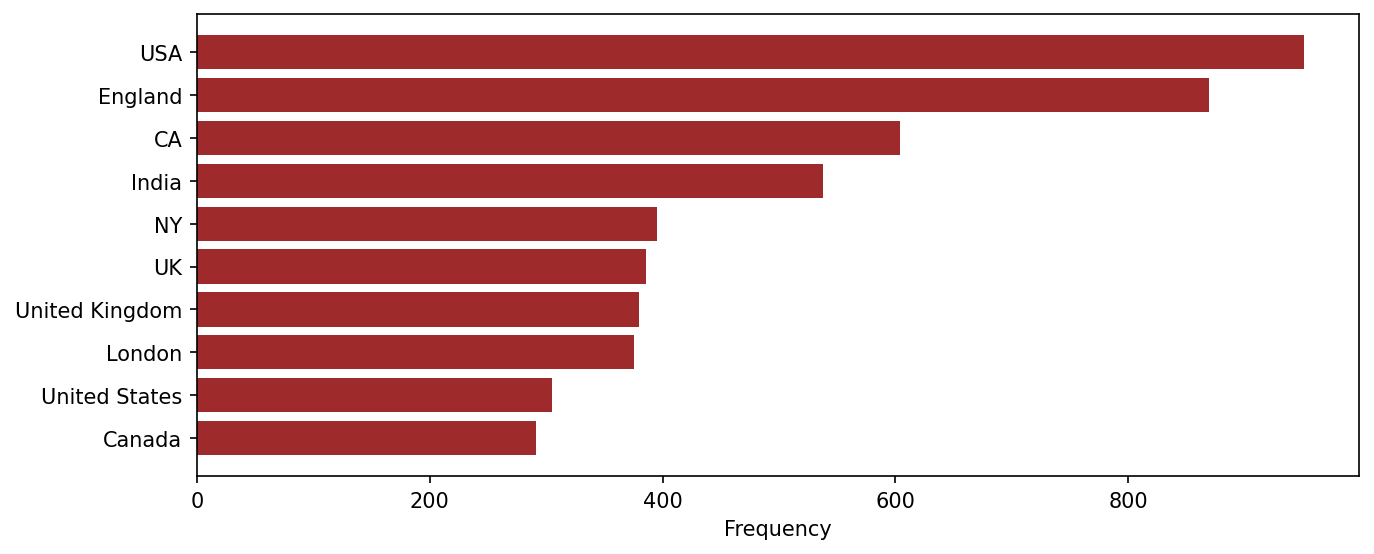

In [ ]:
x = X_train[X_train['WiderLocation'] != 'Unknown']['WiderLocation'].value_counts().head(10)
plt.figure(figsize = (10,4), dpi = 150)
plt.barh(x.index, x.values, color = '#9e2a2b')
plt.gca().invert_yaxis()
plt.xlabel('Frequency')

Закодируйте признак WiderLocation с помощью OHE таким образом, чтобы создались только столбцы для местоположений, которые встречаются более одного раза. Сколько таких значений?


In [ ]:
from sklearn.preprocessing import OneHotEncoder

locations = X_train['WiderLocation'].value_counts()
popular_locations = locations[locations > 1].index.tolist()
print(len(popular_locations))
print(len(locations))

1002
4857


In [ ]:
ohe = OneHotEncoder(sparse_output=True, handle_unknown='ignore', min_frequency=2)
X_train_ohe = ohe.fit_transform(X_train[['WiderLocation']])
X_test_ohe = ohe.transform(X_test[['WiderLocation']])

Добавьте этот признак к матрице отскалированных текстовых признаков, обучите логистическую регрессию, замерьте качество. Как оно изменилось? Оказался ли признак полезным?


*Подсказка:* используйте параметр `categories` в энкодере.

In [ ]:
from scipy.sparse import hstack

In [ ]:
X_train_final = hstack([X_train_cv_scaled, X_train_ohe])
X_test_final = hstack([X_test_cv_scaled, X_test_ohe])

In [ ]:
lg_cv_scaled_final = LogisticRegression(random_state=52)

#Обучаем логистическую регрессию на векторе из Countvectorizer
lg_cv_scaled_final.fit(X_train_final , Y_train)

#Делаем предсказание для Countvectorizer
prediction_cv_train = lg_cv_scaled_final.predict(X_train_final)
prediction_cv_test = lg_cv_scaled_final.predict(X_test_final)

In [ ]:
accuracy_cv_train = accuracy_score(prediction_cv_train, Y_train)
accuracy_cv_test = accuracy_score(prediction_cv_test, Y_test)

print(f"CountVectorizer \n Accuracy on train: {np.round(accuracy_cv_train*100, 3)}% \n Accuracy on test: {np.round(accuracy_cv_test*100, 3)}%")
# CountVectorizer
# Accuracy on train: 94.122%
# Accuracy on test: 84.503%

CountVectorizer 
 Accuracy on train: 94.49% 
 Accuracy on test: 84.463%


**Ответ:** Коронавирус оказал одинаково негативное влияние на весь мир, поэтому привязка к локации не является признаком, влияющим на реакции людей. Это, по своей сути, доказывает наш последний эксперимент, поскольку разницы практически нет по сравнению с результатом, который мы получили без использования данных о локации.